# Chapter 17: Score Function and Energy-Based Models — Interactive Coding Project

Welcome to the companion coding project for **Chapter 17 (Score Function and Energy-Based Models)** of *Mathematics for AI and Machine Learning* (`math4ai.org`).

This notebook provides self-contained **NumPy** and **PyTorch** implementations and numerical verifications for all **5 Exercise Topics** in Chapter 17:
1. **Experiment 1 (Exercises 1 & 2)**: Stein Score Normalization Invariance, Gaussian Score, Affine Transformation Rule, and Conservative EBM Fields vs. Non-Conservative Vector Fields.
2. **Experiment 2 (Exercise 3)**: Explicit Score Matching vs. Hyvärinen Integration-by-Parts Score Matching ($\frac{1}{2}\|\mathbf{s}_\theta\|_2^2 + \nabla\cdot\mathbf{s}_\theta$).
3. **Experiment 3 (Exercise 4)**: Denoising Score Matching (DSM) Conditional Score Identity and Noise Scale Regimes ($\sigma \to 0$ vs. $\sigma \to \infty$).
4. **Experiment 4 (Exercise 5)**: From Score to Sampling — Langevin Dynamics, Fokker–Planck Stationarity, and Multi-Scale Annealed Langevin Sampling.


In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (12, 4.8),
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
np.random.seed(42)
torch.manual_seed(42)
print("Environment initialized successfully.")


Environment initialized successfully.


---
## Experiment 1: Stein Score Geometry, Affine Rule & Conservative EBM Fields (Exercises 1 & 2)

### Mathematical Recap
- **Exercise 1 (Stein Score & Affine Rule)**:
  - For $p(\mathbf{x}) = Z^{-1}\tilde{p}(\mathbf{x})$, $\mathbf{s}(\mathbf{x}) = \nabla_{\mathbf{x}}\log p(\mathbf{x}) = \nabla_{\mathbf{x}}\log\tilde{p}(\mathbf{x})$ is independent of $Z$.
  - For $\mathbf{x}\sim\mathcal{N}(\boldsymbol\mu,\boldsymbol\Sigma)$, $\mathbf{s}(\mathbf{x}) = -\boldsymbol\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu)$ points toward $\boldsymbol\mu$.
  - Under an invertible affine map $\mathbf{y} = A\mathbf{x} + \mathbf{b}$, the score transforms via $\mathbf{s}_{\mathbf{y}}(\mathbf{y}) = A^{-\top}\mathbf{s}_{\mathbf{x}}(A^{-1}(\mathbf{y}-\mathbf{b}))$.
- **Exercise 2 (Energy-Based Models & Conservative Fields)**:
  - For $p_\theta(\mathbf{x}) = Z_\theta^{-1}\exp(-E_\theta(\mathbf{x}))$, $\mathbf{s}_\theta(\mathbf{x}) = -\nabla_{\mathbf{x}}E_\theta(\mathbf{x})$.
  - By the Poincaré lemma on $\mathbb{R}^d$, a smooth vector field $\mathbf{s}(\mathbf{x})$ is conservative ($\mathbf{s} = -\nabla E$) if and only if its Jacobian $J_{\mathbf{s}}(\mathbf{x})$ is symmetric everywhere ($J_{\mathbf{s}} = J_{\mathbf{s}}^\top$).


Ex 1 | Max affine transformation error ||S_y_formula - S_y_direct||_inf: 6.66e-16
Ex 1 | Min inner product (mu - x)^T s(x) across 100 points: 0.1009 > 0
Ex 2 | Conservative EBM ||J - J^T||_F:     0.00e+00
Ex 2 | Non-conservative field ||J - J^T||_F: 2.2627


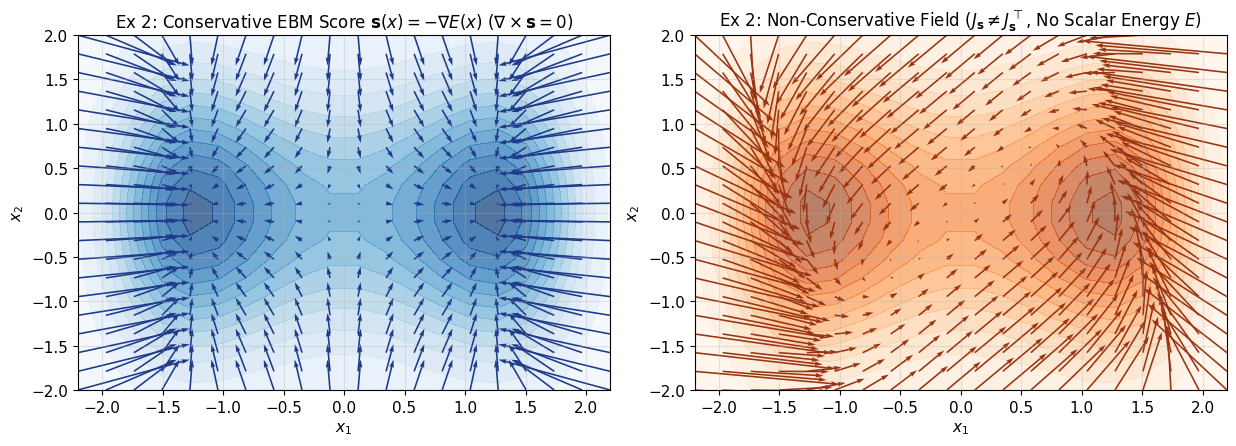

In [2]:
# Ex 1: Verify Affine Transformation Rule s_y(y) = A^{-T} s_x(A^{-1}(y - b))
mu_x = np.array([1.2, -0.7])
Sigma_x = np.array([[1.4, 0.5], [0.5, 0.9]])
A_mat = np.array([[1.8, -0.6], [0.4, 1.3]])
b_vec = np.array([-0.5, 0.9])

rng = np.random.default_rng(42)
X_test = rng.normal(size=(100, 2))
Y_test = X_test @ A_mat.T + b_vec

# Score via affine formula
S_x = -(X_test - mu_x) @ np.linalg.inv(Sigma_x).T
S_y_formula = S_x @ np.linalg.inv(A_mat)  # since (A^{-T} s_x^T)^T = s_x A^{-1}

# Direct score of Y ~ N(A mu_x + b, A Sigma_x A^T)
mu_y = A_mat @ mu_x + b_vec
Sigma_y = A_mat @ Sigma_x @ A_mat.T
S_y_direct = -(Y_test - mu_y) @ np.linalg.inv(Sigma_y).T
print(f"Ex 1 | Max affine transformation error ||S_y_formula - S_y_direct||_inf: {np.max(np.abs(S_y_formula - S_y_direct)):.2e}")

# Verify mode attraction (mu_x - x)^T s_x(x) > 0 for all x != mu_x
dot_products = np.sum((mu_x - X_test) * S_x, axis=1)
print(f"Ex 1 | Min inner product (mu - x)^T s(x) across 100 points: {np.min(dot_products):.4f} > 0")

# Ex 2: Conservative EBM score field vs. Non-conservative rotational field in PyTorch
x_probe = torch.tensor([0.9, -0.7], dtype=torch.float64, requires_grad=True)

def energy_fn(z):
    # Double-well 2D energy: E(z) = 0.25*(z_0^2 - 1.5)^2 + 0.5*z_1^2
    return 0.25 * (z[0]**2 - 1.5)**2 + 0.5 * (z[1]**2)

def score_conservative(z):
    E = energy_fn(z)
    return -torch.autograd.grad(E, z, create_graph=True)[0]

def score_rotational(z):
    # Non-conservative field adding swirl (-z_1, z_0)
    return score_conservative(z) + 0.8 * torch.stack([-z[1], z[0]])

J_cons = torch.autograd.functional.jacobian(score_conservative, x_probe)
J_rot = torch.autograd.functional.jacobian(score_rotational, x_probe)
print(f"Ex 2 | Conservative EBM ||J - J^T||_F:     {torch.norm(J_cons - J_cons.T).item():.2e}")
print(f"Ex 2 | Non-conservative field ||J - J^T||_F: {torch.norm(J_rot - J_rot.T).item():.4f}")

# Plot conservative EBM score field vs non-conservative swirl field
g1 = np.linspace(-2.2, 2.2, 20)
g2 = np.linspace(-2.0, 2.0, 20)
G1, G2 = np.meshgrid(g1, g2)
E_grid = 0.25 * (G1**2 - 1.5)**2 + 0.5 * (G2**2)
U_cons = -G1 * (G1**2 - 1.5)
V_cons = -G2
U_rot = U_cons - 1.2 * G2
V_rot = V_cons + 1.2 * G1

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].contourf(G1, G2, np.exp(-E_grid), levels=15, cmap="Blues", alpha=0.7)
axes[0].quiver(G1, G2, U_cons, V_cons, color="#1e3a8a", scale=35)
axes[0].set_title(r"Ex 2: Conservative EBM Score $\mathbf{s}(x) = -\nabla E(x)$ ($\nabla \times \mathbf{s} = 0$)")
axes[0].set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")

axes[1].contourf(G1, G2, np.exp(-E_grid), levels=15, cmap="Oranges", alpha=0.6)
axes[1].quiver(G1, G2, U_rot, V_rot, color="#9a3412", scale=35)
axes[1].set_title(r"Ex 2: Non-Conservative Field ($J_{\mathbf{s}} \neq J_{\mathbf{s}}^\top$, No Scalar Energy $E$)")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
plt.tight_layout()
plt.show()


---
## Experiment 2: Hyvärinen Score Matching via Integration by Parts (Exercise 3)

### Mathematical Recap
- **Explicit Score Matching (ESM)**:
  $$\mathcal{J}_{\mathrm{ESM}}(\theta) = \frac{1}{2}\mathbb{E}_{p_{\mathrm{data}}}\!\left[\|\mathbf{s}_\theta(\mathbf{x}) - \nabla_{\mathbf{x}}\log p_{\mathrm{data}}(\mathbf{x})\|_2^2\right]$$
- **Implicit / Hyvärinen Score Matching (ISM)**: Using integration by parts under boundary decay $p_{\mathrm{data}}(\mathbf{x})\mathbf{s}_\theta(\mathbf{x}) \to \mathbf{0}$,
  $$\mathcal{J}_{\mathrm{ISM}}(\theta) = \mathbb{E}_{p_{\mathrm{data}}}\!\left[\frac{1}{2}\|\mathbf{s}_\theta(\mathbf{x})\|_2^2 + \nabla_{\mathbf{x}}\cdot\mathbf{s}_\theta(\mathbf{x})\right] = \mathcal{J}_{\mathrm{ESM}}(\theta) - \frac{1}{2}\mathbb{E}_{p_{\mathrm{data}}}\!\left[\|\nabla_{\mathbf{x}}\log p_{\mathrm{data}}(\mathbf{x})\|_2^2\right]$$
  In 1D, this simplifies to $\mathbb{E}_{p_{\mathrm{data}}}\!\left[\frac{1}{2}s_\theta(x)^2 + s_\theta'(x)\right]$.


Ex 3 | Final Explicit SM Loss: 0.0218 | Final (Hyvarinen ISM + C): -0.0621


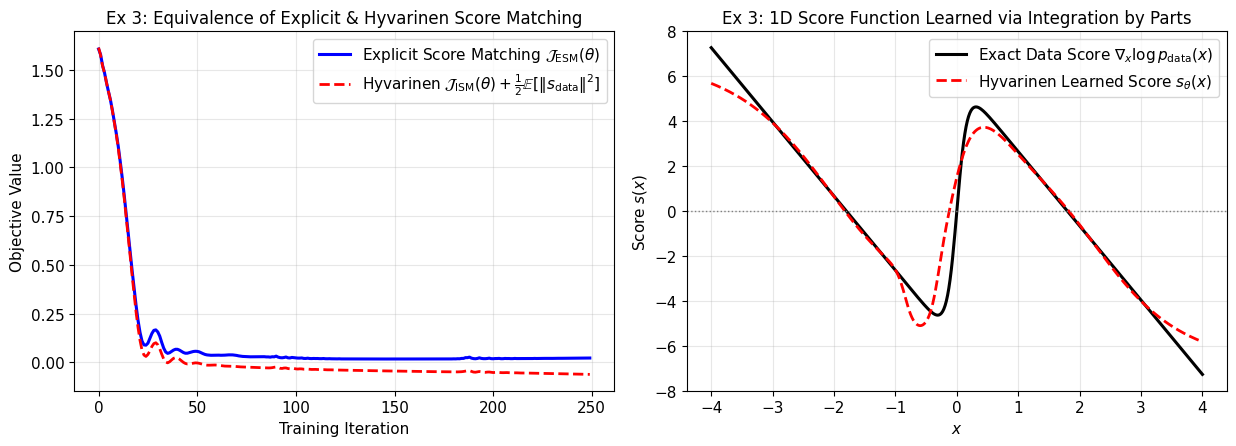

In [3]:
# Ex 3: Train a 1D Neural Score Model using Hyvarinen's Integration-by-Parts Objective in PyTorch
torch.manual_seed(42)
N_sm = 4000
# 1D Bimodal Gaussian Mixture: 0.5 N(-1.8, 0.55^2) + 0.5 N(+1.8, 0.55^2)
comp_sm = np.random.choice([-1.8, 1.8], size=N_sm)
x_sm_np = comp_sm + 0.55 * np.random.randn(N_sm)
x_sm = torch.tensor(x_sm_np, dtype=torch.float32).unsqueeze(1)

def true_bimodal_score_np(x, m=1.8, s=0.55):
    w1 = np.exp(-0.5 * (x + m)**2 / s**2)
    w2 = np.exp(-0.5 * (x - m)**2 / s**2)
    p1 = w1 / (w1 + w2 + 1e-15)
    return p1 * (-(x + m) / s**2) + (1.0 - p1) * (-(x - m) / s**2)

s_true_samples = torch.tensor(true_bimodal_score_np(x_sm_np), dtype=torch.float32).unsqueeze(1)
const_fisher = float(0.5 * torch.mean(s_true_samples**2).item())

score_mlp = torch.nn.Sequential(
    torch.nn.Linear(1, 32),
    torch.nn.Tanh(),
    torch.nn.Linear(32, 32),
    torch.nn.Tanh(),
    torch.nn.Linear(32, 1),
)
opt_sm = torch.optim.Adam(score_mlp.parameters(), lr=0.01)

ism_hist, esm_hist = [], []
for step in range(250):
    x_in = x_sm.clone().detach().requires_grad_(True)
    s_pred = score_mlp(x_in)
    ds_dx = torch.autograd.grad(s_pred.sum(), x_in, create_graph=True)[0]
    loss_ism = torch.mean(0.5 * (s_pred**2) + ds_dx)
    opt_sm.zero_grad(); loss_ism.backward(); opt_sm.step()

    with torch.no_grad():
        loss_esm = 0.5 * torch.mean((s_pred - s_true_samples)**2)
        ism_hist.append(float(loss_ism.item() + const_fisher))
        esm_hist.append(float(loss_esm.item()))

print(f"Ex 3 | Final Explicit SM Loss: {esm_hist[-1]:.4f} | Final (Hyvarinen ISM + C): {ism_hist[-1]:.4f}")

x_eval = np.linspace(-4.0, 4.0, 400)
with torch.no_grad():
    s_learned = score_mlp(torch.tensor(x_eval, dtype=torch.float32).unsqueeze(1)).squeeze().numpy()
s_exact = true_bimodal_score_np(x_eval)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].plot(esm_hist, "b-", lw=2.2, label=r"Explicit Score Matching $\mathcal{J}_{\mathrm{ESM}}(\theta)$")
axes[0].plot(ism_hist, "r--", lw=2, label=r"Hyvarinen $\mathcal{J}_{\mathrm{ISM}}(\theta) + \frac{1}{2}\mathbb{E}[\|s_{\mathrm{data}}\|^2]$")
axes[0].set_title("Ex 3: Equivalence of Explicit & Hyvarinen Score Matching")
axes[0].set_xlabel("Training Iteration")
axes[0].set_ylabel("Objective Value")
axes[0].legend()

axes[1].plot(x_eval, s_exact, "k-", lw=2.2, label=r"Exact Data Score $\nabla_x \log p_{\mathrm{data}}(x)$")
axes[1].plot(x_eval, s_learned, "r--", lw=2, label=r"Hyvarinen Learned Score $s_\theta(x)$")
axes[1].axhline(0, color="gray", lw=1, ls=":")
axes[1].set_title("Ex 3: 1D Score Function Learned via Integration by Parts")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("Score $s(x)$")
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Experiment 3: Denoising Score Matching & Multi-Scale Noise Regimes (Exercise 4)

### Mathematical Recap
- **Gaussian Perturbation Kernel**: Given $\tilde{\mathbf{x}} = \mathbf{x} + \boldsymbol\epsilon$ with $\boldsymbol\epsilon \sim \mathcal{N}(\mathbf{0}, \sigma^2\mathbf{I})$, the conditional score is:
  $$\nabla_{\tilde{\mathbf{x}}}\log p_\sigma(\tilde{\mathbf{x}}\mid\mathbf{x}) = -\frac{\tilde{\mathbf{x}}-\mathbf{x}}{\sigma^2} = -\frac{\boldsymbol\epsilon}{\sigma^2}$$
- **Denoising Score Matching (DSM) Objective**:
  $$\mathcal{J}_{\mathrm{DSM}}(\theta) = \frac{1}{2}\mathbb{E}_{\mathbf{x},\boldsymbol\epsilon}\!\left[\left\|\mathbf{s}_\theta(\mathbf{x}+\boldsymbol\epsilon) + \frac{\boldsymbol\epsilon}{\sigma^2}\right\|_2^2\right]$$
  whose unique minimizer is the smoothed data score $\mathbf{s}_\theta^*(\tilde{\mathbf{x}}) = \nabla_{\tilde{\mathbf{x}}}\log p_\sigma(\tilde{\mathbf{x}})$.
- **Effect of $\sigma$**: As $\sigma \to 0$, $p_\sigma$ resolves sharp local modes; as $\sigma \to \infty$, $p_\sigma$ blurs all modes into a single wide Gaussian centered at $\mathbb{E}[\mathbf{x}]$.


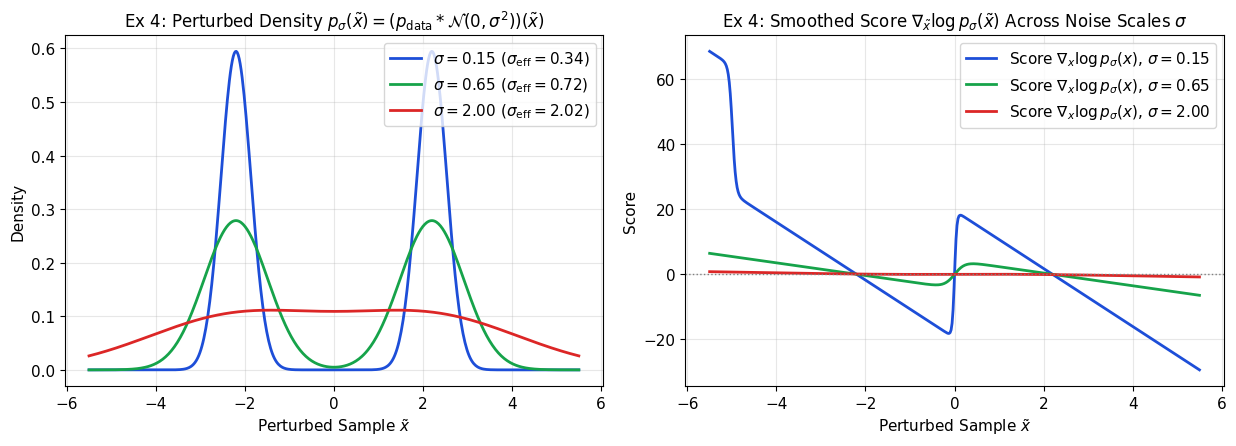

Ex 4 | sigma=0.15 -> effective std=0.335, score at x=0.5 is +15.1111
Ex 4 | sigma=0.65 -> effective std=0.716, score at x=0.5 is +3.2013
Ex 4 | sigma=2.00 -> effective std=2.022, score at x=0.5 is +0.0190


In [4]:
# Ex 4: Analytical & Empirical DSM Score across Noise Scales sigma in {0.15, 0.65, 2.00}
# True data: 0.5 N(-2.2, 0.3^2) + 0.5 N(+2.2, 0.3^2)
# Convolving with N(0, sigma^2) gives p_sigma(x) = 0.5 N(-2.2, 0.3^2 + sigma^2) + 0.5 N(+2.2, 0.3^2 + sigma^2)
sig_data = 0.3
sigmas_dsm = [0.15, 0.65, 2.00]
x_grid_dsm = np.linspace(-5.5, 5.5, 500)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
colors_dsm = ["#1d4ed8", "#16a34a", "#dc2626"]

for sig, col in zip(sigmas_dsm, colors_dsm):
    s_eff = np.sqrt(sig_data**2 + sig**2)
    p1 = (1.0 / np.sqrt(2 * np.pi * s_eff**2)) * np.exp(-0.5 * (x_grid_dsm + 2.2)**2 / s_eff**2)
    p2 = (1.0 / np.sqrt(2 * np.pi * s_eff**2)) * np.exp(-0.5 * (x_grid_dsm - 2.2)**2 / s_eff**2)
    p_sig = 0.5 * p1 + 0.5 * p2
    score_sig = true_bimodal_score_np(x_grid_dsm, m=2.2, s=s_eff)

    # Verify DSM conditional regression on a concrete neural network for sig=0.65
    axes[0].plot(x_grid_dsm, p_sig, color=col, lw=2, label=f"$\\sigma = {sig:.2f}$ ($\\sigma_{{\\mathrm{{eff}}}}={s_eff:.2f}$)")
    axes[1].plot(x_grid_dsm, score_sig, color=col, lw=2, label=f"Score $\\nabla_{{x}}\\log p_\\sigma(x)$, $\\sigma={sig:.2f}$")

axes[1].axhline(0, color="gray", ls=":", lw=1)
axes[0].set_title(r"Ex 4: Perturbed Density $p_\sigma(\tilde{x}) = (p_{\mathrm{data}} * \mathcal{N}(0, \sigma^2))(\tilde{x})$")
axes[0].set_xlabel(r"Perturbed Sample $\tilde{x}$")
axes[0].set_ylabel("Density")
axes[0].legend()

axes[1].set_title(r"Ex 4: Smoothed Score $\nabla_{\tilde{x}}\log p_\sigma(\tilde{x})$ Across Noise Scales $\sigma$")
axes[1].set_xlabel(r"Perturbed Sample $\tilde{x}$")
axes[1].set_ylabel("Score")
axes[1].legend()
plt.tight_layout()
plt.show()

for sig in sigmas_dsm:
    s_eff = np.sqrt(sig_data**2 + sig**2)
    sc_at_origin = true_bimodal_score_np(np.array([0.5]), m=2.2, s=s_eff)[0]
    print(f"Ex 4 | sigma={sig:.2f} -> effective std={s_eff:.3f}, score at x=0.5 is {sc_at_origin:+.4f}")


---
## Experiment 4: From Score to Sampling — Langevin Dynamics & Fokker–Planck Stationarity (Exercise 5)

### Mathematical Recap
- **Langevin Dynamics Iteration**:
  $$\mathbf{x}_{k+1} = \mathbf{x}_k + \eta\,\mathbf{s}(\mathbf{x}_k) + \sqrt{2\eta}\,\boldsymbol\epsilon_k, \quad \boldsymbol\epsilon_k \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$$
  - Without the Brownian term $\sqrt{2\eta}\boldsymbol\epsilon_k$, pure gradient ascent collapses all samples onto point modes ($\nabla_{\mathbf{x}}\log p(\mathbf{x}) = \mathbf{0}$).
  - With $\sqrt{2\eta}\boldsymbol\epsilon_k$, the Fokker–Planck probability flux $\mathbf{J} = \rho\nabla\log p - \nabla\rho$ vanishes at $\rho(\mathbf{x}) = p(\mathbf{x})$, guaranteeing that $p(\mathbf{x})$ is the stationary distribution.


Ex 5 | Pure Gradient Ascent intra-mode std: 0.00000 (Mode Collapse!)
Ex 5 | Langevin Dynamics    intra-mode std: 0.5985 (True std = 0.6000)


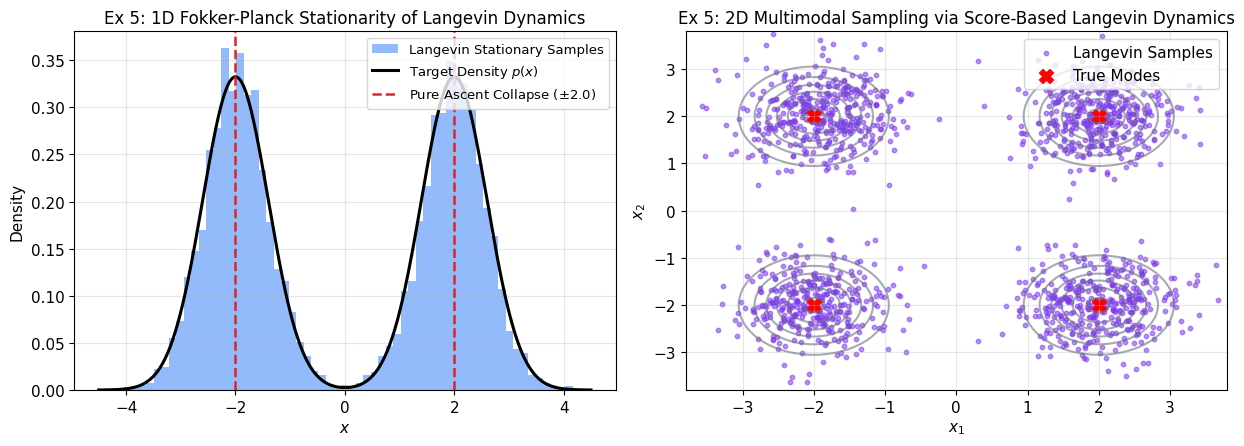

In [5]:
# Ex 5: 1D & 2D Langevin Dynamics vs. Pure Score Gradient Ascent
rng = np.random.default_rng(42)
N_particles = 5000
x_init_1d = rng.uniform(-4.5, 4.5, size=N_particles)
x_ascent = x_init_1d.copy()
x_langevin = x_init_1d.copy()
eta_1d = 0.01

for _ in range(700):
    x_ascent = x_ascent + eta_1d * true_bimodal_score_np(x_ascent, m=2.0, s=0.6)
    x_langevin = x_langevin + eta_1d * true_bimodal_score_np(x_langevin, m=2.0, s=0.6) + np.sqrt(2 * eta_1d) * rng.normal(size=N_particles)

print(f"Ex 5 | Pure Gradient Ascent intra-mode std: {x_ascent[x_ascent > 0].std():.5f} (Mode Collapse!)")
print(f"Ex 5 | Langevin Dynamics    intra-mode std: {x_langevin[x_langevin > 0].std():.4f} (True std = 0.6000)")

# 2D 4-Mode Mixture Sampling via Langevin Dynamics
modes_2d = np.array([[-2.0, -2.0], [-2.0, 2.0], [2.0, -2.0], [2.0, 2.0]])
def score_4modes(X, s=0.55):
    # X: (N, 2)
    diffs = X[:, None, :] - modes_2d[None, :, :]  # (N, 4, 2)
    log_w = -0.5 * np.sum(diffs**2, axis=-1) / (s**2)
    log_w -= np.max(log_w, axis=1, keepdims=True)
    w = np.exp(log_w)
    w /= np.sum(w, axis=1, keepdims=True)  # responsibilities (N, 4)
    return -np.sum(w[:, :, None] * diffs, axis=1) / (s**2)

X_2d = rng.uniform(-4.0, 4.0, size=(1500, 2))
eta_2d = 0.015
for _ in range(500):
    X_2d = X_2d + eta_2d * score_4modes(X_2d) + np.sqrt(2 * eta_2d) * rng.normal(size=X_2d.shape)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
x_dense = np.linspace(-4.5, 4.5, 400)
p_true_1d = 0.5 * (1.0 / np.sqrt(2 * np.pi * 0.6**2)) * (np.exp(-0.5 * (x_dense + 2.0)**2 / 0.6**2) + np.exp(-0.5 * (x_dense - 2.0)**2 / 0.6**2))
axes[0].hist(x_langevin, bins=60, density=True, alpha=0.55, color="#3b82f6", label="Langevin Stationary Samples")
axes[0].plot(x_dense, p_true_1d, "k-", lw=2.2, label=r"Target Density $p(x)$")
axes[0].axvline(-2.0, color="#dc2626", ls="--", lw=1.8, label=r"Pure Ascent Collapse ($\pm 2.0$)")
axes[0].axvline(2.0, color="#dc2626", ls="--", lw=1.8)
axes[0].set_title("Ex 5: 1D Fokker-Planck Stationarity of Langevin Dynamics")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=9.5)

g_2d = np.linspace(-3.8, 3.8, 100)
GX, GY = np.meshgrid(g_2d, g_2d)
pts_grid = np.stack([GX, GY], axis=-1)
P_2d = np.zeros_like(GX)
for m_pt in modes_2d:
    P_2d += 0.25 * np.exp(-0.5 * ((GX - m_pt[0])**2 + (GY - m_pt[1])**2) / (0.55**2))
axes[1].contour(GX, GY, P_2d, levels=6, colors="#6b7280", alpha=0.6)
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], s=10, alpha=0.55, color="#7c3aed", label="Langevin Samples")
axes[1].scatter(modes_2d[:, 0], modes_2d[:, 1], c="red", marker="X", s=100, label="True Modes")
axes[1].set_title("Ex 5: 2D Multimodal Sampling via Score-Based Langevin Dynamics")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()
